# IMEX and Delay Equations

This notebook covers two families of steppers for problems the explicit ODE steppers handle poorly:

- **IMEX (implicit–explicit)** steppers for $y' = f_{exp}(y, t) + f_{imp}(y, t)$, where $f_{imp}$ is stiff (fast linear decay, diffusion along a cable) and $f_{exp}$ is nonstiff but possibly expensive or nonlinear: `imex_euler_step` (order 1), `imex_ars222_step` (order 2, L-stable), `imex_cnab_step` (order 2, two-step).
- **DDE** steppers for delay equations $y'(t) = f(t, y(t), y(t - \tau_1), \dots)$: `dde_euler_step`, `dde_heun_step`, `dde_rk4_step`, and the predictor–corrector variants `dde_euler_pc_step`, `dde_heun_pc_step`.

## 1. Setup

In [1]:
import brainstate
import jax
import jax.numpy as jnp
import matplotlib.pyplot as plt
import numpy as np

import braintools

jax.config.update("jax_enable_x64", True)

## 2. IMEX Steppers

### Calling convention

`step(f_exp, f_imp, y, t, *args, max_iter=2)`, with both parts of the form `f(y, t, *args)`. `imex_cnab_step` additionally needs the previous state: `imex_cnab_step(f_exp, f_imp, y, y_prev, t, ...)`.

Each implicit stage $Y = c + a\,\Delta t\,f_{imp}(Y, t^*)$ is solved with **Newton's method**; `max_iter` is the number of Newton iterations. For states with up to 256 elements the Jacobian is formed densely; larger states use matrix-free GMRES on Jacobian-vector products. When $f_{imp}$ is linear in $y$, one iteration is exact.

### Accuracy and stiffness

The test problem $y' = \sin t - k y$ has the exact solution $y(t) = (1 - B)e^{-kt} + A \sin t + B \cos t$ with $A = k/(k^2+1)$, $B = -1/(k^2+1)$. We treat $\sin t$ explicitly and $-ky$ implicitly.

In [2]:
def forced_decay(name, k, dt, T=1.0):
    fe = lambda y, t: jnp.sin(t)
    fi = lambda y, t: -k * y
    n = int(round(T / dt))
    with brainstate.environ.context(dt=dt):
        if name == "imex_cnab_step":
            # two-step method: start with one ARS(2,2,2) step
            y1 = braintools.quad.imex_ars222_step(fe, fi, jnp.asarray(1.0), 0.0)

            def body(carry, i):
                y, y_prev = carry
                return (braintools.quad.imex_cnab_step(fe, fi, y, y_prev, i * dt), y), None

            (y, _), _ = jax.lax.scan(body, (y1, jnp.asarray(1.0)), jnp.arange(1, n))
        else:
            step = getattr(braintools.quad, name)
            y, _ = jax.lax.scan(lambda y, i: (step(fe, fi, y, i * dt), None), jnp.asarray(1.0), jnp.arange(n))
    return float(y)

def exact_forced_decay(k, T=1.0):
    A, B = k / (k ** 2 + 1), -1 / (k ** 2 + 1)
    return (1 - B) * np.exp(-k * T) + A * np.sin(T) + B * np.cos(T)

names = ["imex_euler_step", "imex_ars222_step", "imex_cnab_step"]
dts = [0.1, 0.05, 0.025, 0.0125]
for name in names:
    e = np.array([abs(forced_decay(name, 2.0, dt) - exact_forced_decay(2.0)) for dt in dts])
    print(f"{name:18s} k = 2: order {np.round(np.log2(e[:-1] / e[1:]), 2)}")
print()
for k, dt in [(100, 0.05), (1000, 0.01), (1e6, 0.01)]:
    row = "   ".join(f"{name}: {forced_decay(name, k, dt):.3e}" for name in names)
    print(f"k = {k:<8g} k*dt = {k * dt:<6g} exact {exact_forced_decay(k):.3e}   {row}")

imex_euler_step    k = 2: order [1.1  1.05 1.03]
imex_ars222_step   k = 2: order [1.99 1.99 2.  ]


imex_cnab_step     k = 2: order [1.69 1.89 1.96]

k = 100      k*dt = 5      exact 8.360e-03   imex_euler_step: 8.073e-03   imex_ars222_step: 8.424e-03   imex_cnab_step: 8.370e-03


k = 1000     k*dt = 10     exact 8.409e-04   imex_euler_step: 8.355e-04   imex_ars222_step: 8.427e-04   imex_cnab_step: 8.410e-04
k = 1e+06    k*dt = 10000  exact 8.415e-07   imex_euler_step: 8.360e-07   imex_ars222_step: 8.454e-07   imex_cnab_step: 4.645e-04


All three reach their nominal order, and all remain stable with $k\,\Delta t$ in the thousands, where any explicit method would explode (RK4 needs $k\,\Delta t < 2.79$). At $k\,\Delta t = 10^4$, however, CNAB returns a value far from the solution. The reason is its implicit part, the trapezoidal rule: it is A-stable but not **L-stable**, so a very fast mode is not damped but flips sign every step with an amplification factor close to $-1$:

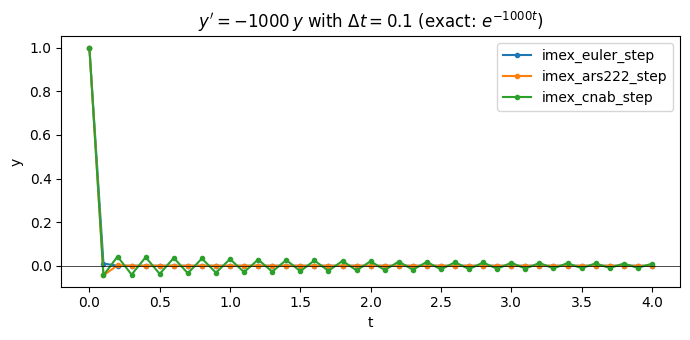

In [3]:
k, dt, n = 1000.0, 0.1, 40          # k * dt = 100
fe = lambda y, t: jnp.zeros_like(y)
fi = lambda y, t: -k * y
paths = {name: [1.0] for name in names}
with brainstate.environ.context(dt=dt):
    for name in ["imex_euler_step", "imex_ars222_step"]:
        y = jnp.asarray(1.0)
        for i in range(n):
            y = getattr(braintools.quad, name)(fe, fi, y, i * dt)
            paths[name].append(float(y))
    y_prev, y = jnp.asarray(1.0), braintools.quad.imex_ars222_step(fe, fi, jnp.asarray(1.0), 0.0)
    paths["imex_cnab_step"].append(float(y))
    for i in range(1, n):
        y_prev, y = y, braintools.quad.imex_cnab_step(fe, fi, y, y_prev, i * dt)
        paths["imex_cnab_step"].append(float(y))

plt.figure(figsize=(7, 3.5))
for name, p in paths.items():
    plt.plot(np.arange(n + 1) * dt, p, ".-", label=name)
plt.axhline(0, color="k", lw=0.5)
plt.xlabel("t"); plt.ylabel("y"); plt.title("$y' = -1000\\,y$ with $\\Delta t = 0.1$ (exact: $e^{-1000 t}$)")
plt.legend(); plt.tight_layout(); plt.show()

IMEX Euler and ARS(2,2,2) damp the fast mode immediately, as the exact solution does. CNAB carries it along as a slowly decaying sawtooth. Use CNAB when the implicit part is stiff but its fastest modes do not matter or are not excited (smooth initial data), and ARS(2,2,2) when fast transients must be damped.

### Nonlinear implicit parts and `max_iter`

For a nonlinear $f_{imp}$, each Newton iteration roughly squares the error. With $f_{imp}(y) = -1000\,y^3$, $y_0 = 1$ and $\Delta t = 0.01$, the IMEX Euler step must solve $Y + 10\,Y^3 = 1$:

In [4]:
root = [r.real for r in np.roots([10, 0, 1, -1]) if abs(r.imag) < 1e-12][0]
with brainstate.environ.context(dt=0.01):
    for max_iter in range(1, 7):
        y = braintools.quad.imex_euler_step(lambda y, t: 0.0 * y, lambda y, t: -1000.0 * y ** 3,
                                            jnp.asarray(1.0), 0.0, max_iter=max_iter)
        print(f"max_iter = {max_iter}:  Y = {float(y):.12f}   error {abs(float(y) - root):.1e}")

max_iter = 1:  Y = 0.677419354839   error 2.8e-01
max_iter = 2:  Y = 0.488749116319   error 9.6e-02
max_iter = 3:  Y = 0.408387836861   error 1.5e-02
max_iter = 4:  Y = 0.393479727265   error 4.8e-04
max_iter = 5:  Y = 0.393003214565   error 4.8e-07
max_iter = 6:  Y = 0.393002738972   error 4.7e-13


The default `max_iter=2` is exact for linear implicit parts and adequate for mildly nonlinear ones; raise it when the implicit part is strongly nonlinear over a step, as here.

### Example: a FitzHugh–Nagumo cable

A cable of excitable membrane, discretized into $N = 500$ compartments of length $\Delta x = 0.1$:

$$\partial_t v = D\,\partial_{xx} v + v - v^3/3 - w, \qquad \partial_t w = \varepsilon\,(v + a - b w).$$

The diffusion term is stiff: its fastest mode decays at rate $4D/\Delta x^2 = 400$, which restricts RK4 to $\Delta t < 0.007$, although the wave itself evolves on a time scale of order 1. We treat diffusion implicitly and the local membrane dynamics explicitly. The state is a dict of two arrays (1000 elements), so the Newton steps use matrix-free GMRES.

In [5]:
N, dx, D, eps, a, b = 500, 0.1, 1.0, 0.08, 0.7, 0.8
x = np.arange(N) * dx

def laplacian(v):  # no-flux boundaries
    vp = jnp.concatenate([v[:1], v, v[-1:]])
    return (vp[2:] - 2 * v + vp[:-2]) / dx ** 2

def membrane(s, t):   # explicit part
    return {"v": s["v"] - s["v"] ** 3 / 3 - s["w"], "w": eps * (s["v"] + a - b * s["w"])}

def diffusion(s, t):  # implicit part
    return {"v": D * laplacian(s["v"]), "w": jnp.zeros_like(s["w"])}

def full_rhs(s, t):
    return jax.tree.map(jnp.add, membrane(s, t), diffusion(s, t))

s0 = {"v": jnp.full(N, -1.2).at[:20].set(1.5), "w": jnp.full(N, -0.62)}

def run_cable(step, dt, T=40.0, imex=True):
    n = int(round(T / dt))
    with brainstate.environ.context(dt=dt):
        def body(s, i):
            s = step(membrane, diffusion, s, i * dt) if imex else step(full_rhs, s, i * dt)
            return s, s["v"]
        _, vs = jax.lax.scan(body, s0, jnp.arange(n))
    return np.asarray(vs)

def front_position(v):  # rightmost crossing of v = 0, linearly interpolated
    i = np.where((v[:-1] > 0) & (v[1:] <= 0))[0][-1]
    return x[i] + v[i] / (v[i] - v[i + 1]) * dx

v_ref = run_cable(braintools.quad.ode_rk4_step, 0.002, imex=False)
print(f"RK4, dt = 0.002:  front at t = 40: {front_position(v_ref[-1]):.3f}")
for dt in [0.005, 0.01]:
    vs = run_cable(braintools.quad.ode_rk4_step, dt, imex=False)
    print(f"RK4, dt = {dt}:  " + (f"front {front_position(vs[-1]):.3f}" if np.all(np.isfinite(vs)) else "diverged"))
for name in ["imex_euler_step", "imex_ars222_step"]:
    for dt in [0.05, 0.1, 0.2]:
        vs = run_cable(getattr(braintools.quad, name), dt)
        print(f"{name}, dt = {dt}:  front {front_position(vs[-1]):.3f}")

RK4, dt = 0.002:  front at t = 40: 34.383
RK4, dt = 0.005:  front 34.383


RK4, dt = 0.01:  diverged


imex_euler_step, dt = 0.05:  front 33.854


imex_euler_step, dt = 0.1:  front 33.348


imex_euler_step, dt = 0.2:  front 32.399


imex_ars222_step, dt = 0.05:  front 34.380


imex_ars222_step, dt = 0.1:  front 34.368


imex_ars222_step, dt = 0.2:  front 34.320


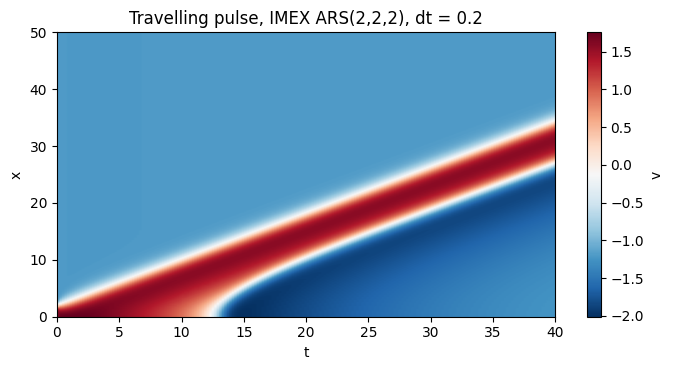

In [6]:
vs = run_cable(braintools.quad.imex_ars222_step, 0.2)
plt.figure(figsize=(7, 3.8))
plt.imshow(vs.T, aspect="auto", origin="lower", extent=[0, 40, 0, N * dx], cmap="RdBu_r")
plt.colorbar(label="v")
plt.xlabel("t"); plt.ylabel("x"); plt.title("Travelling pulse, IMEX ARS(2,2,2), dt = 0.2")
plt.tight_layout(); plt.show()

RK4 diverges at `dt = 0.01`, just above its stability limit. IMEX ARS(2,2,2) keeps the pulse front within 0.06 of the reference at `dt = 0.2`, a step 40 times larger than the largest stable RK4 step. IMEX Euler is stable too, but first order: its front lags by 2 space units at `dt = 0.2`, and the lag halves with the step.

Each IMEX step costs more than an explicit step (a Newton solve with GMRES iterations), so the saving in wall time is smaller than the saving in steps. It grows with stiffness: halving $\Delta x$ quarters the explicit stability limit but leaves the IMEX step unchanged.

## 3. Delay Differential Equations

### Calling convention

`step(f, y, t, history_fn, delays, *args)`. Note the different argument order of the right-hand side: `f(t, y, y_delayed_1, y_delayed_2, ..., *args)`, time first. `delays` is one delay or a list; `history_fn(s)` must return the state at any past time $s$, including times between grid points and, for the initial interval, the prescribed initial function.

You are responsible for the history. Inside `jax.lax.scan`, a convenient approach is to carry a buffer of all past values on the time grid and interpolate in it.

### Interpolation limits the order

The test equation $y'(t) = -y(t - 1)$ with $y(t) = 1$ for $t \le 0$ has a piecewise-polynomial exact solution, obtained by integrating interval by interval (*method of steps*). We compare **linear** interpolation of the history with **cubic Hermite** interpolation, which also uses the stored derivatives.

In [7]:
import math

def dde_exact(t):
    n = int(np.floor(t)) + 1
    return sum((-1) ** k * (t - (k - 1)) ** k / math.factorial(k) for k in range(n + 1))

f_dde = lambda t, y, y_delayed: -y_delayed
T, tau = 3.0, 1.0

def solve_dde(step, dt, interpolation):
    n = int(round(T / dt))
    t_grid = jnp.arange(n + 1) * dt
    ys, dys = jnp.ones(n + 1), jnp.zeros(n + 1)   # values and derivatives on the grid

    def body(carry, i):
        ys, dys = carry

        def history(s):
            if interpolation == "linear":
                inside = jnp.interp(s, t_grid, ys)
            else:  # cubic Hermite on [t_j, t_j+1]
                j = jnp.clip(jnp.floor(s / dt).astype(int), 0, n - 1)
                h = (s - t_grid[j]) / dt
                inside = ((2 * h ** 3 - 3 * h ** 2 + 1) * ys[j] + (h ** 3 - 2 * h ** 2 + h) * dt * dys[j]
                          + (-2 * h ** 3 + 3 * h ** 2) * ys[j + 1] + (h ** 3 - h ** 2) * dt * dys[j + 1])
            return jnp.where(s <= 0, 1.0, inside)   # initial function for s <= 0

        t = i * dt
        dys = dys.at[i].set(f_dde(t, ys[i], history(t - tau)))
        ys = ys.at[i + 1].set(step(f_dde, ys[i], t, history, tau))
        return (ys, dys), None

    with brainstate.environ.context(dt=dt):
        (ys, _), _ = jax.lax.scan(body, (ys, dys), jnp.arange(n))
    return float(ys[-1])

dts = [0.1, 0.05, 0.025, 0.0125]
for name in ["dde_euler_step", "dde_euler_pc_step", "dde_heun_step", "dde_heun_pc_step", "dde_rk4_step"]:
    for interpolation in ["linear", "hermite"]:
        e = np.array([abs(solve_dde(getattr(braintools.quad, name), dt, interpolation) - dde_exact(T)) for dt in dts])
        orders = np.log2(e[:-1] / np.maximum(e[1:], 1e-300))
        print(f"{name:18s} {interpolation:8s} error at dt=0.0125: {e[-1]:.1e}   orders {np.round(orders, 2)}")

dde_euler_step     linear   error at dt=0.0125: 6.3e-03   orders [1.05 1.02 1.01]
dde_euler_step     hermite  error at dt=0.0125: 6.3e-03   orders [1.05 1.02 1.01]


dde_euler_pc_step  linear   error at dt=0.0125: 6.2e-03   orders [0.95 0.98 0.99]


dde_euler_pc_step  hermite  error at dt=0.0125: 5.2e-03   orders [0.95 1.18 1.04]


dde_heun_step      linear   error at dt=0.0125: 1.3e-05   orders [2. 2. 2.]


dde_heun_step      hermite  error at dt=0.0125: 1.3e-05   orders [2. 2. 2.]


dde_heun_pc_step   linear   error at dt=0.0125: 1.3e-05   orders [2. 2. 2.]


dde_heun_pc_step   hermite  error at dt=0.0125: 1.3e-05   orders [2. 2. 2.]


dde_rk4_step       linear   error at dt=0.0125: 1.3e-05   orders [2. 2. 2.]


dde_rk4_step       hermite  error at dt=0.0125: 7.2e-16   orders [ 1.   -3.32 -1.38]


- The Euler-type steppers are first order and the Heun-type steppers second order, with either interpolation.
- RK4 with **linear** interpolation is only second order: its intermediate stages query the history between grid points, where linear interpolation has an $O(\Delta t^2)$ error.
- With **cubic Hermite** interpolation, RK4 is exact up to round-off here: the solution is a piecewise cubic polynomial on $[0, 3]$, which both the interpolant and the method reproduce exactly (orders computed from round-off-level errors are meaningless). In general, cubic Hermite interpolation is what fourth-order accuracy requires.

The `jnp.where(s <= 0, 1.0, ...)` in `history` matters. The solution has a kink at $t = 0$ (its derivative jumps from 0 to $-1$); interpolating across it with the derivative stored at $t = 0$ costs RK4 an order. Delay equations propagate such kinks to $t = \tau, 2\tau, \dots$, so choose $\Delta t$ such that the delays are multiples of it.

### Example: oscillations from delayed inhibition

A population with delayed inhibitory self-feedback,

$$\tau\,r'(t) = -r(t) + F\big(I - w\,r(t - d)\big), \qquad F(x) = \frac{1}{1 + e^{-x}},$$

has a fixed point at $r^* = 0.5$ for $I = w/2$. Linearizing, perturbations obey $\tau x' = -x - \tfrac{w}{4}\,x(t - d)$, which loses stability through a Hopf bifurcation when the delay exceeds

$$d_c = \tau\,\frac{\pi - \arctan \omega\tau}{\omega\tau}, \qquad \omega\tau = \sqrt{(w/4)^2 - 1}.$$

With $\tau = 10$ ms and $w = 10$, $d_c \approx 8.7$ ms. We integrate with `dde_heun_step` and a linearly interpolated buffer (enough for a second-order method):

predicted critical delay: 8.65 ms


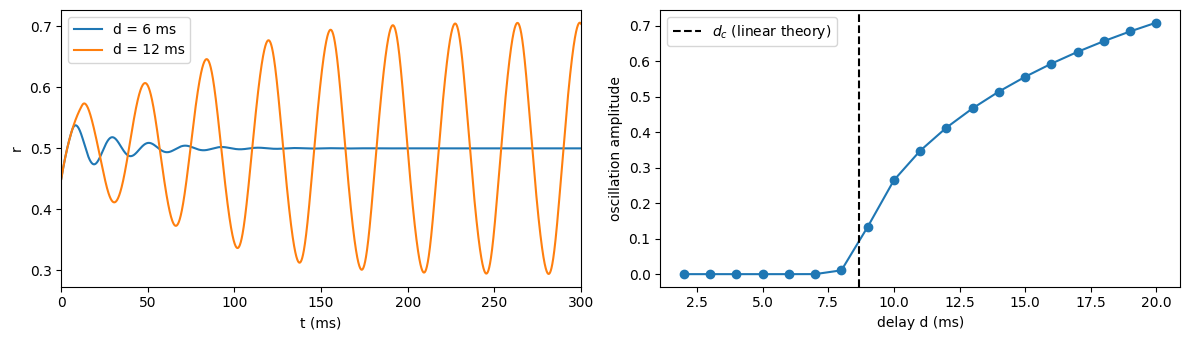

In [8]:
tau_r, w, I = 10.0, 10.0, 5.0
F = lambda x: 1.0 / (1.0 + jnp.exp(-x))
rate_rhs = lambda t, r, r_delayed: (-r + F(I - w * r_delayed)) / tau_r

def simulate_delay(d, dt=0.05, T=600.0, r0=0.45):
    n = int(round(T / dt))
    t_grid = jnp.arange(n + 1) * dt
    rs = jnp.full(n + 1, r0)

    def body(rs, i):
        history = lambda s: jnp.where(s <= 0, r0, jnp.interp(s, t_grid, rs))
        r_next = braintools.quad.dde_heun_step(rate_rhs, rs[i], i * dt, history, d)
        return rs.at[i + 1].set(r_next), None

    with brainstate.environ.context(dt=dt):
        rs, _ = jax.lax.scan(body, rs, jnp.arange(n))
    return np.asarray(t_grid), np.asarray(rs)

omega_tau = np.sqrt((w / 4) ** 2 - 1)
d_c = tau_r * (np.pi - np.arctan(omega_tau)) / omega_tau
print(f"predicted critical delay: {d_c:.2f} ms")

delays = np.arange(2.0, 20.1, 1.0)
amplitudes = []
for d in delays:
    ts, rs = simulate_delay(d)
    tail = rs[ts > 400]
    amplitudes.append(tail.max() - tail.min())

fig, ax = plt.subplots(1, 2, figsize=(12, 3.5))
for d in [6.0, 12.0]:
    ts, rs = simulate_delay(d)
    ax[0].plot(ts, rs, label=f"d = {d:g} ms")
ax[0].set_xlim(0, 300); ax[0].set_xlabel("t (ms)"); ax[0].set_ylabel("r"); ax[0].legend()
ax[1].plot(delays, amplitudes, "o-")
ax[1].axvline(d_c, color="k", ls="--", label="$d_c$ (linear theory)")
ax[1].set_xlabel("delay d (ms)"); ax[1].set_ylabel("oscillation amplitude"); ax[1].legend()
plt.tight_layout(); plt.show()

Below $d_c$ the perturbation decays to the fixed point; above it, a stable oscillation appears whose amplitude grows with the delay. The simulated onset, between 8 and 9 ms, agrees with the linear prediction of 8.65 ms. The small amplitude at $d = 8$ ms is a slowly decaying transient: near the bifurcation, perturbations decay slowly.

## Summary

- IMEX steppers split the right-hand side into an explicit and an implicit part; the implicit stages are solved with Newton's method (dense for small states, matrix-free GMRES for large ones). `max_iter` counts Newton iterations: one suffices for linear implicit parts.
- `imex_euler_step` is first order, `imex_ars222_step` and `imex_cnab_step` second order. ARS(2,2,2) is L-stable and damps very fast modes; CNAB is a cheaper two-step method that lets them oscillate.
- Implicit treatment of stiff linear terms such as cable diffusion permits steps far beyond the explicit stability limit.
- DDE right-hand sides take time first: `f(t, y, *delayed)`. You provide `history_fn`; its interpolation must match the order of the method (linear for Euler/Heun, cubic Hermite for RK4), and it must return the initial function for times before the start.